# 阶段 2 · 作业 F：从零搭建小型 U-Net

**师兄的要求：从零搭建一个小型 U-Net，结构正确即可。**

上一项 MNIST 作业把每张图像变成 10 个类别分数。本项建立一个可以输出整张图像的网络，为下一项去噪训练准备模型。

本实验保留 U-Net 的编码器、瓶颈、解码器和两条拼接式跳跃连接。使用两次下采样，基础通道数为 16，并给 3×3 卷积设置 `padding=1`，使卷积块保持空间尺寸。这是便于学习和后续去噪的小型实现；原论文采用更深的结构和不同的边界处理。

将文件保存到项目的 `assignments/09_unet_structure/`，选择之前的 `dl-env` 内核。只需要已有的 `torch、numpy、matplotlib`，不用下载数据，不依赖 MNIST 权重。

| 小节 | 工作 |
|---|---|
| 1—3 | 设置环境，定义双卷积块，搭建 U-Net |
| 4—5 | 逐项核对尺寸，理解通道拼接 |
| 6 | 检查不同批量、不同图像尺寸 |
| 7 | 用一个小批量检查反向传播能否到达全部参数 |
| 8—9 | 画结构图，保存检查结果，整理一次重点 |

建议先运行到第 4 节，看懂张量尺寸，再继续后面的检查。文件附有参考运行输出；重新运行后会替换成你的结果。


## 1. 导入工具，设置路径与设备

采用 PyTorch 的图像布局 `(N, C, H, W)`：批量、通道、高度、宽度。灰度图像有 1 个输入通道，本项也输出 1 个通道。

输入高度和宽度都要求是 4 的倍数，因为网络有两次 2 倍下采样。这样可以直接拼接同尺度特征；本次把这个限制写清楚并检查，不额外加入裁剪或插值逻辑。


In [1]:
import json
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import torch
from torch import nn

torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.manual_seed(2029)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(2029)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG = {
    "in_channels": 1,
    "out_channels": 1,
    "base_channels": 16,
    "downsampling_levels": 2,
    "convolution_kernel": 3,
    "convolution_padding": 1,
    "upsampling": "ConvTranspose2d(kernel_size=2, stride=2)",
    "skip_connection": "concatenate along channel dimension",
    "output_activation": "linear",
    "training_updates": 0,
    "seed": 2029,
}

cwd = Path.cwd()
candidate = cwd / "assignments" / "09_unet_structure"
ASSIGNMENT_DIR = candidate if candidate.is_dir() else cwd
OUTPUT_DIR = ASSIGNMENT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("PyTorch 版本：", torch.__version__)
print("设备：", DEVICE)
print("结果位置：", OUTPUT_DIR.resolve())
print("输入要求：(N, 1, H, W)，H 和 W 均为 4 的倍数")


PyTorch 版本： 2.5.1+cpu
设备： cpu
结果位置： [参考运行目录]/09_unet_structure/outputs
输入要求：(N, 1, H, W)，H 和 W 均为 4 的倍数


## 2. 定义基本模块：DoubleConv

一个双卷积块包含：`卷积 → ReLU → 卷积 → ReLU`。

例如，`DoubleConv(1, 16)` 把 `(N, 1, 128, 128)` 变成 `(N, 16, 128, 128)`。第一个卷积把通道数从 1 变成 16，第二个卷积在 16 个通道之间继续提取特征。

每个卷积的核大小为 3、步幅为 1、填充为 1，所以：

\[
H_{out}=\left\lfloor\frac{H+2\times1-3}{1}\right\rfloor+1=H.
\]

这里的 16 张特征图是从同一张输入图像学习到的不同表示。`N` 始终表示图片数量。


In [2]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.layers(x)


block = DoubleConv(1, 16).to(DEVICE)
with torch.no_grad():
    block_output = block(torch.zeros(2, 1, 128, 128, device=DEVICE))
print("双卷积块：(2, 1, 128, 128) →", tuple(block_output.shape))
assert tuple(block_output.shape) == (2, 16, 128, 128)
del block, block_output


双卷积块：(2, 1, 128, 128) → (2, 16, 128, 128)


## 3. 搭建 SmallUNet

编码器先用双卷积块提取特征，再用最大池化减小空间尺寸。瓶颈在最小分辨率上处理特征。解码器用转置卷积提高分辨率，并与同一尺度的编码器特征拼接。

这条跳跃连接让解码器能直接使用编码器保留的高分辨率信息。拼接增加通道数；后面的卷积负责融合这些信息。

本例转置卷积取 `kernel_size=2, stride=2, padding=0`，因此输出高度为 `(H-1)×2+2=2H`，宽度同理。它的权重会参与学习，不表示精确撤销之前的池化。

最后的 1×1 卷积将 16 个特征通道映射为一个输出强度通道。为了后续像素回归，这里采用线性输出。下一项去噪训练会使用像素误差损失。

`return_features=True` 只用于本次观察中间张量；之后通常调用 `model(images)`，直接得到输出图像。


In [3]:
class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=16):
        super().__init__()
        self.in_channels = in_channels
        c = base_channels

        # 编码器：空间尺寸逐步减半，通道数增加
        self.enc1 = DoubleConv(in_channels, c)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc2 = DoubleConv(c, 2 * c)

        # 瓶颈
        self.bottleneck = DoubleConv(2 * c, 4 * c)

        # 解码器：上采样后，与编码器同尺度特征拼接
        self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(4 * c, 2 * c)
        self.up1 = nn.ConvTranspose2d(2 * c, c, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(2 * c, c)

        # 每个空间位置输出一个像素强度
        self.output_conv = nn.Conv2d(c, out_channels, kernel_size=1)

    def forward(self, x, return_features=False):
        if x.ndim != 4:
            raise ValueError("输入必须是四维张量 (N, C, H, W)。")
        if x.shape[1] != self.in_channels:
            raise ValueError(f"输入通道应为 {self.in_channels}，实际为 {x.shape[1]}。")
        height, width = x.shape[-2:]
        if height < 4 or width < 4 or height % 4 != 0 or width % 4 != 0:
            raise ValueError("本学习版要求高度、宽度至少为 4，且都为 4 的倍数。")

        e1 = self.enc1(x)
        p1 = self.pool(e1)
        e2 = self.enc2(p1)
        p2 = self.pool(e2)
        b = self.bottleneck(p2)

        u2 = self.up2(b)
        c2 = torch.cat([u2, e2], dim=1)
        d2 = self.dec2(c2)

        u1 = self.up1(d2)
        c1 = torch.cat([u1, e1], dim=1)
        d1 = self.dec1(c1)
        output = self.output_conv(d1)

        if return_features:
            features = {
                "input": x, "enc1": e1, "pool1": p1,
                "enc2": e2, "pool2": p2, "bottleneck": b,
                "up2": u2, "concat2": c2, "dec2": d2,
                "up1": u1, "concat1": c1, "dec1": d1,
                "output": output,
            }
            return output, features
        return output


## 4. 跟着一批图像核对全部尺寸

输入设置为两张 128×128 灰度图像：`(2, 1, 128, 128)`。下表省略批量维度 `N=2`。

| 名称 | 通道 C | 高度 H | 宽度 W | 操作 |
|---|---:|---:|---:|---|
| input | 1 | 128 | 128 | 输入 |
| enc1 | 16 | 128 | 128 | 双卷积 |
| pool1 | 16 | 64 | 64 | 最大池化 |
| enc2 | 32 | 64 | 64 | 双卷积 |
| pool2 | 32 | 32 | 32 | 最大池化 |
| bottleneck | 64 | 32 | 32 | 双卷积 |
| up2 | 32 | 64 | 64 | 转置卷积 |
| concat2 | 64 | 64 | 64 | 与 enc2 拼接：32+32 |
| dec2 | 32 | 64 | 64 | 双卷积融合 |
| up1 | 16 | 128 | 128 | 转置卷积 |
| concat1 | 32 | 128 | 128 | 与 enc1 拼接：16+16 |
| dec1 | 16 | 128 | 128 | 双卷积融合 |
| output | 1 | 128 | 128 | 1×1 卷积 |

尺寸相同表示输出与输入具有相同的像素网格；输出像素的数值由模型参数决定。当前参数仍是随机初始化，尚未学过去噪。


In [4]:
torch.manual_seed(CONFIG["seed"])
model = SmallUNet(
    in_channels=CONFIG["in_channels"],
    out_channels=CONFIG["out_channels"],
    base_channels=CONFIG["base_channels"],
).to(DEVICE)

model.eval()
trace_input = torch.rand(2, 1, 128, 128, device=DEVICE)
with torch.no_grad():
    trace_output, features = model(trace_input, return_features=True)

expected_shapes = {
    "input": (2, 1, 128, 128),
    "enc1": (2, 16, 128, 128),
    "pool1": (2, 16, 64, 64),
    "enc2": (2, 32, 64, 64),
    "pool2": (2, 32, 32, 32),
    "bottleneck": (2, 64, 32, 32),
    "up2": (2, 32, 64, 64),
    "concat2": (2, 64, 64, 64),
    "dec2": (2, 32, 64, 64),
    "up1": (2, 16, 128, 128),
    "concat1": (2, 32, 128, 128),
    "dec1": (2, 16, 128, 128),
    "output": (2, 1, 128, 128),
}

shape_report = {}
for name, expected in expected_shapes.items():
    actual = tuple(features[name].shape)
    assert actual == expected, (name, actual, expected)
    shape_report[name] = list(actual)
    print(f"{name:12s} {str(actual):24s} 通过")

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert torch.isfinite(trace_output).all().item()
print("\n可训练参数数量：", f"{parameter_count:,}")
print("输入与输出尺寸相同：", trace_input.shape == trace_output.shape)


input        (2, 1, 128, 128)         通过
enc1         (2, 16, 128, 128)        通过
pool1        (2, 16, 64, 64)          通过
enc2         (2, 32, 64, 64)          通过
pool2        (2, 32, 32, 32)          通过
bottleneck   (2, 64, 32, 32)          通过
up2          (2, 32, 64, 64)          通过
concat2      (2, 64, 64, 64)          通过
dec2         (2, 32, 64, 64)          通过
up1          (2, 16, 128, 128)        通过
concat1      (2, 32, 128, 128)        通过
dec1         (2, 16, 128, 128)        通过
output       (2, 1, 128, 128)         通过

可训练参数数量： 116,753
输入与输出尺寸相同： True


## 5. 跳跃连接为什么拼接后是 64 个通道？

以第二层为例：`u2` 和 `e2` 都是 `(2, 32, 64, 64)`。PyTorch 维度从 0 编号，`dim=1` 对应通道，所以 `torch.cat([u2, e2], dim=1)` 得到 `(2, 64, 64, 64)`。

`cat` 把两组通道按顺序放到一起，批量大小和空间尺寸保持一致。前 32 个通道来自上采样，后 32 个来自编码器。之后的 `DoubleConv(64, 32)` 再学习融合它们。

下面用值为 1 和 2 的小张量直观看到这个过程：


In [5]:
a = torch.ones(1, 2, 3, 3)
b = torch.full((1, 2, 3, 3), 2.0)
joined = torch.cat([a, b], dim=1)

print("a 的形状：", tuple(a.shape))
print("b 的形状：", tuple(b.shape))
print("拼接后的形状：", tuple(joined.shape))
print("同一个空间位置，沿通道取出的值：", joined[0, :, 0, 0].tolist())
assert torch.equal(joined[0, :, 0, 0], torch.tensor([1., 1., 2., 2.]))

assert torch.equal(features["concat2"][:, :32], features["up2"])
assert torch.equal(features["concat2"][:, 32:], features["enc2"])
assert torch.equal(features["concat1"][:, :16], features["up1"])
assert torch.equal(features["concat1"][:, 16:], features["enc1"])
print("两条跳跃连接的通道内容检查：通过")

# 观察完毕后释放这些中间特征
del features, trace_input, trace_output


a 的形状： (1, 2, 3, 3)
b 的形状： (1, 2, 3, 3)
拼接后的形状： (1, 4, 3, 3)
同一个空间位置，沿通道取出的值： [1.0, 1.0, 2.0, 2.0]
两条跳跃连接的通道内容检查：通过


## 6. 不同尺寸与批量也能前向传播

本模型完全由卷积、池化、上采样构成，没有按某个固定像素总数设置的全连接层。因此，输入尺寸可以变化，只要满足本学习版规定的 4 倍数条件。

下面检查单张 28×28、两张 64×96、单张 128×128。最后使用高度为 126 的例子，确认尺寸限制能给出清楚的提示。这个异常会在代码中接住，单元仍应正常完成。


In [6]:
size_checks = []
model.eval()
with torch.no_grad():
    for input_shape in [(1, 1, 28, 28), (2, 1, 64, 96), (1, 1, 128, 128)]:
        x = torch.rand(*input_shape, device=DEVICE)
        y = model(x)
        assert tuple(y.shape) == input_shape
        assert torch.isfinite(y).all().item()
        size_checks.append({"input": list(input_shape), "output": list(y.shape)})
        print(input_shape, "→", tuple(y.shape), "通过")

try:
    model(torch.zeros(1, 1, 126, 128, device=DEVICE))
except ValueError as exc:
    print("\n预期的尺寸提示：", exc)
    rejected_invalid_size = True
else:
    raise AssertionError("应当明确拒绝不满足要求的尺寸。")


(1, 1, 28, 28) → (1, 1, 28, 28) 通过
(2, 1, 64, 96) → (2, 1, 64, 96) 通过
(1, 1, 128, 128) → (1, 1, 128, 128) 通过

预期的尺寸提示： 本学习版要求高度、宽度至少为 4，且都为 4 的倍数。


## 7. 用一个小批量检查反向传播

搭建网络还要确认损失可以对全部参数求导。这里临时生成两张 64×64 几何图像，加入标准差为 0.08 的高斯噪声，用它们做一次结构检查。

`MSELoss` 衡量输出像素与目标像素的平均平方误差：

\[
L=\frac{1}{NCHW}\sum_{n,c,h,w}(\hat I_{nchw}-I_{nchw})^2.
\]

调用一次 `backward()`，检查每组参数是否获得有限梯度。这里没有调用优化器更新参数，所以损失值只帮助确认计算过程有效，不能当作去噪性能结果。下一项才会构建训练/验证数据并训练模型。


In [7]:
coordinates = torch.linspace(-1, 1, 64)
yy, xx = torch.meshgrid(coordinates, coordinates, indexing="ij")
square = ((xx.abs() < 0.55) & (yy.abs() < 0.55)).float()
circle = ((xx + 0.15).square() + (yy - 0.1).square() < 0.45 ** 2).float()
clean_batch = torch.stack([0.1 + 0.7 * square, 0.1 + 0.7 * circle]).unsqueeze(1)
noise_generator = torch.Generator().manual_seed(2030)
noise = 0.08 * torch.randn(clean_batch.shape, generator=noise_generator)
noisy_batch = clean_batch + noise

clean_batch = clean_batch.to(DEVICE)
noisy_batch = noisy_batch.to(DEVICE)
criterion = nn.MSELoss()
model.train()
model.zero_grad(set_to_none=True)
prediction = model(noisy_batch)
loss = criterion(prediction, clean_batch)
assert prediction.shape == clean_batch.shape
assert torch.isfinite(loss).item()
loss.backward()

gradient_report = []
for name, parameter in model.named_parameters():
    assert parameter.grad is not None, f"{name} 没有连接到损失。"
    assert torch.isfinite(parameter.grad).all().item(), f"{name} 出现非有限梯度。"
    gradient_report.append({
        "parameter": name,
        "shape": list(parameter.shape),
        "gradient_norm": float(parameter.grad.norm().item()),
        "finite": True,
    })

print("输入 / 目标 / 输出：", tuple(noisy_batch.shape), tuple(clean_batch.shape),
      tuple(prediction.shape))
print("结构检查使用的 MSE：", f"{loss.item():.6f}")
print("获得有限梯度的参数张量：", len(gradient_report), "/", len(list(model.parameters())))
print("反向传播检查：通过；本实验参数更新次数为 0")
model.zero_grad(set_to_none=True)


输入 / 目标 / 输出： (2, 1, 64, 64) (2, 1, 64, 64) (2, 1, 64, 64)
结构检查使用的 MSE： 0.114109
获得有限梯度的参数张量： 26 / 26
反向传播检查：通过；本实验参数更新次数为 0


## 8. 画出这个网络的 U 形结构

图中标注 `C × H × W`，省略批量维度。蓝色为编码器，黄色为瓶颈，绿色为解码器。横向箭头表示同一尺度的跳跃连接，箭头到达的位置会沿通道拼接，再做双卷积融合。

顶部跳跃连接把 `enc1` 传给 `dec1` 前的拼接，第二条把 `enc2` 传给 `dec2` 前的拼接。上采样只能提高分辨率；如何根据特征得到有用的像素值，需要后续训练。


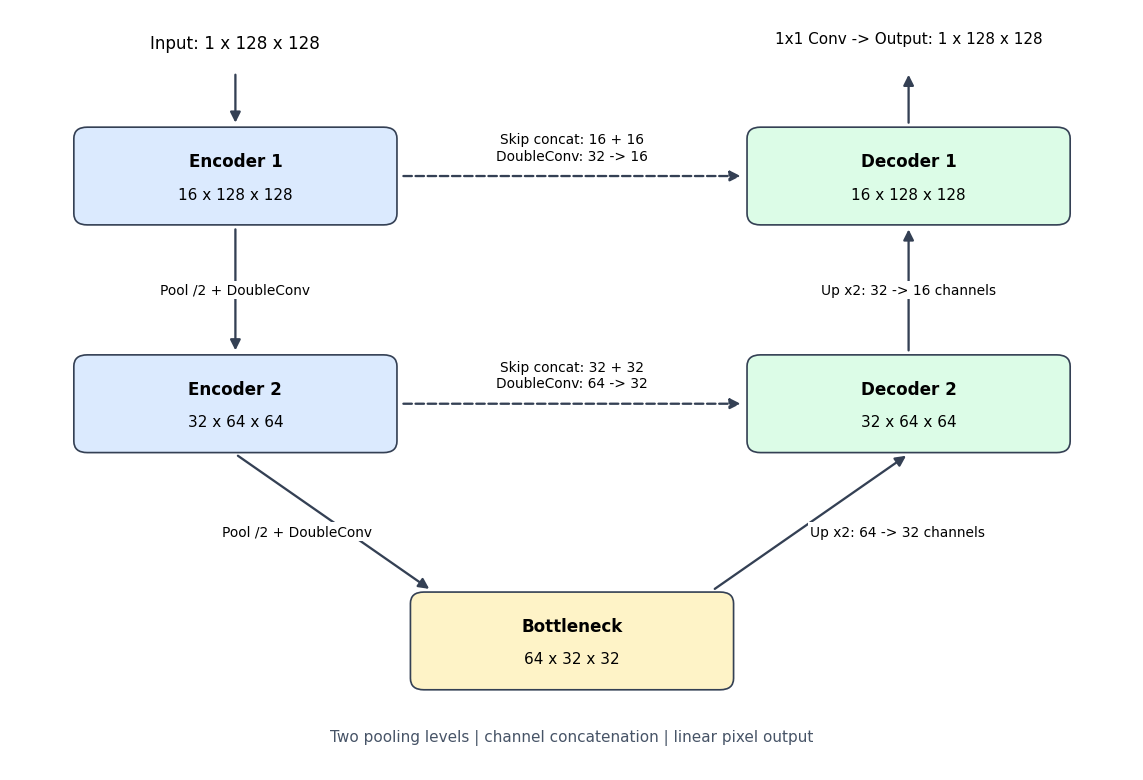

结构图已保存： [参考运行目录]/09_unet_structure/outputs/unet_architecture.png


In [8]:
fig, ax = plt.subplots(figsize=(10.5, 7.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 8)
ax.axis("off")


def draw_box(center, title, detail, color, width=2.8, height=0.95):
    cx, cy = center
    patch = FancyBboxPatch(
        (cx - width / 2, cy - height / 2), width, height,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=color, edgecolor="#344054", linewidth=1.1,
    )
    ax.add_patch(patch)
    ax.text(cx, cy + 0.16, title, ha="center", va="center", weight="bold", fontsize=11)
    ax.text(cx, cy - 0.19, detail, ha="center", va="center", fontsize=10)


def draw_arrow(start, end, label=None, text_at=None, dashed=False):
    arrow = FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color="#344054", linestyle="--" if dashed else "-",
    )
    ax.add_patch(arrow)
    if label:
        tx, ty = text_at
        ax.text(tx, ty, label, ha="center", va="center", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})


draw_box((2, 6.25), "Encoder 1", "16 x 128 x 128", "#dbeafe")
draw_box((2, 3.85), "Encoder 2", "32 x 64 x 64", "#dbeafe")
draw_box((5, 1.35), "Bottleneck", "64 x 32 x 32", "#fef3c7")
draw_box((8, 3.85), "Decoder 2", "32 x 64 x 64", "#dcfce7")
draw_box((8, 6.25), "Decoder 1", "16 x 128 x 128", "#dcfce7")

ax.text(2, 7.60, "Input: 1 x 128 x 128", ha="center", fontsize=11)
draw_arrow((2, 7.35), (2, 6.78))
draw_arrow((2, 5.72), (2, 4.38), "Pool /2 + DoubleConv", (2, 5.05))
draw_arrow((2, 3.32), (3.75, 1.88), "Pool /2 + DoubleConv", (2.55, 2.50))
draw_arrow((6.25, 1.88), (8, 3.32), "Up x2: 64 -> 32 channels", (7.9, 2.50))
draw_arrow((8, 4.38), (8, 5.72), "Up x2: 32 -> 16 channels", (8, 5.05))

draw_arrow((3.47, 3.85), (6.53, 3.85),
           "Skip concat: 32 + 32\nDoubleConv: 64 -> 32", (5, 4.15), dashed=True)
draw_arrow((3.47, 6.25), (6.53, 6.25),
           "Skip concat: 16 + 16\nDoubleConv: 32 -> 16", (5, 6.55), dashed=True)
draw_arrow((8, 6.78), (8, 7.35))
ax.text(8, 7.65, "1x1 Conv -> Output: 1 x 128 x 128", ha="center", fontsize=10)
ax.text(5, 0.30, "Two pooling levels | channel concatenation | linear pixel output",
        ha="center", color="#475467", fontsize=10)
fig.tight_layout()
architecture_path = OUTPUT_DIR / "unet_architecture.png"
fig.savefig(architecture_path, dpi=160, bbox_inches="tight")
plt.show()
print("结构图已保存：", architecture_path.resolve())


## 9. 保存检查结果，完成作业

保存网络文本、逐层形状、参数数量、不同尺寸测试和梯度检查结果。模型仍处于随机初始化状态；下一项训练需要复用结构，并正式构建数据、训练循环和验证过程。

完成标准：

- 能解释 `128 → 64 → 32 → 64 → 128` 的尺寸变化。
- 能解释两处通道拼接：`32+32=64`、`16+16=32`。
- 正常输入的形状检查通过，输出为 `(N, 1, H, W)`。
- 所有参数张量均获得有限梯度。
- 理解本项完成的是模型搭建与检查，去噪效果由后续训练评估。

完成后，只把下面这些重点补进 Obsidian 的已有笔记即可：

> **U-Net 要点**：编码器通过下采样处理不同尺度的特征；解码器通过上采样恢复空间尺寸。跳跃连接沿通道拼接同尺度编码器特征，后续卷积负责融合。最后用 1×1 卷积输出每个像素的强度。本学习版采用两次下采样、3×3 卷积加 padding=1，输入 H、W 为 4 的倍数；结构正确还需要检查前向尺寸与反向梯度，正式去噪训练在下一项完成。

参考资料：[U-Net 原论文](https://arxiv.org/abs/1505.04597)、[PyTorch ConvTranspose2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html)、[PyTorch torch.cat](https://docs.pytorch.org/docs/stable/generated/torch.cat.html)。


In [9]:
report = {
    "task": "stage2_F_small_unet_structure",
    "config": CONFIG,
    "device": str(DEVICE),
    "torch_version": str(torch.__version__),
    "trainable_parameters": parameter_count,
    "layer_shapes": shape_report,
    "size_checks": size_checks,
    "invalid_size_rejected": rejected_invalid_size,
    "gradient_check_loss": float(loss.item()),
    "gradient_tensors_checked": len(gradient_report),
    "all_gradients_finite": all(row["finite"] for row in gradient_report),
    "gradients": gradient_report,
    "training_updates": 0,
    "denoising_performance_evaluated": False,
}
(OUTPUT_DIR / "unet_structure_checks.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "unet_model.txt").write_text(str(model) + "\n", encoding="utf-8")
assert report["all_gradients_finite"]
assert report["invalid_size_rejected"]
print("作业 F 的结构检查全部通过。")
print("保存的文件：")
for filename in ["unet_architecture.png", "unet_structure_checks.json", "unet_model.txt"]:
    print(" -", (OUTPUT_DIR / filename).resolve())
print("下一项：使用这个 U-Net 比较“噪声→干净图”与“噪声→噪声图”的去噪训练。")


作业 F 的结构检查全部通过。
保存的文件：
 - [参考运行目录]/09_unet_structure/outputs/unet_architecture.png
 - [参考运行目录]/09_unet_structure/outputs/unet_structure_checks.json
 - [参考运行目录]/09_unet_structure/outputs/unet_model.txt
下一项：使用这个 U-Net 比较“噪声→干净图”与“噪声→噪声图”的去噪训练。
